# Notebook 03 — LSTM Model Training
## American Sign Language (ASL) Detection
---
Loads the landmark sequences, builds a Bidirectional LSTM model, trains it with early stopping,
plots training curves, and saves the best model.

**Why Bidirectional LSTM?**
A BiLSTM reads the 30-frame sequence both forward *and* backward, so it can learn
patterns at any point in the signing motion — not just from the beginning.

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import Bidirectional, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)
print(f'TensorFlow {tf.__version__}')

TensorFlow 2.20.0


In [2]:
# Load landmark sequences from Notebook 02
X_train = np.load('processed_data/X_train.npy')
y_train = np.load('processed_data/y_train.npy')
X_val   = np.load('processed_data/X_val.npy')
y_val   = np.load('processed_data/y_val.npy')
X_test  = np.load('processed_data/X_test.npy')
y_test  = np.load('processed_data/y_test.npy')

with open('processed_data/sequence_config.json') as f:
    cfg = json.load(f)
with open('processed_data/class_names.json') as f:
    class_names = json.load(f)

SEQ_LEN     = cfg['SEQUENCE_LENGTH']
FEAT_SIZE   = cfg['FEATURE_SIZE']
NUM_CLASSES = cfg['NUM_CLASSES']

# One-hot encode labels
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat   = to_categorical(y_val,   NUM_CLASSES)
y_test_cat  = to_categorical(y_test,  NUM_CLASSES)

print(f'X_train : {X_train.shape}  y_train: {y_train.shape}')
print(f'X_val   : {X_val.shape}  y_val  : {y_val.shape}')
print(f'X_test  : {X_test.shape}  y_test : {y_test.shape}')
print(f'Classes : {NUM_CLASSES}  {class_names}')

X_train : (5890, 30, 126)  y_train: (5890,)
X_val   : (150, 30, 126)  y_val  : (150,)
X_test  : (150, 30, 126)  y_test : (150,)
Classes : 30  ['ANGRY', 'ART', 'BAD', 'COME', 'EXCITED', 'FAMILY', 'FRIEND', 'GO', 'GOOD', 'HAPPY', 'HELLO', 'HELP', 'HOME', 'HURT', 'KNOW', 'LOVE', 'MORE', 'NO', 'PLEASE', 'SAD', 'SCARED', 'SORRY', 'STOP', 'THANK YOU', 'THINK', 'TIME', 'TIRED', 'WATER', 'WORK', 'YES']


In [3]:
# Build Bidirectional LSTM model
model = Sequential(name='ASL_BiLSTM')
model.add(layers.Input(shape=(SEQ_LEN, FEAT_SIZE)))

model.add(Bidirectional(LSTM(128, return_sequences=True)))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Bidirectional(LSTM(64)))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(NUM_CLASSES, activation='softmax'))

model.compile(optimizer=Adam(0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "ASL_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 30, 256)        │       261,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 447,390 (1.71 MB)

 Trainable params: 446,622 (1.70 MB)

 Non-trainable params: 768 (3.00 KB)

In [4]:
# Train with early stopping and best-model checkpoint
os.makedirs('models', exist_ok=True)
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True),
    ModelCheckpoint('models/best_lstm_model.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6),
]

history = model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    shuffle=True,
)

best_val_acc = max(history.history['val_accuracy'])
print(f'\nBest validation accuracy: {best_val_acc:.4f}')

Epoch 1/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.0805 - loss: 3.2952 - val_accuracy: 0.1333 - val_loss: 2.7868 - learning_rate: 0.0010
Epoch 2/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.1319 - loss: 2.8016 - val_accuracy: 0.1733 - val_loss: 2.4551 - learning_rate: 0.0010
Epoch 3/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.1849 - loss: 2.5334 - val_accuracy: 0.1333 - val_loss: 2.5141 - learning_rate: 0.0010
Epoch 4/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.2287 - loss: 2.3106 - val_accuracy: 0.2933 - val_loss: 2.2422 - learning_rate: 0.0010
Epoch 5/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.2805 - loss: 2.0730 - val_accuracy: 0.3067 - val_loss: 2.0474 - learning_rate: 0.0010
Epoch 6/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.3698 - loss: 1.8138 - val_accuracy: 0.3800 - val_loss: 1.9054 - learning_rate: 0.0010
Epoch 7/100
185/185 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.4462 - l

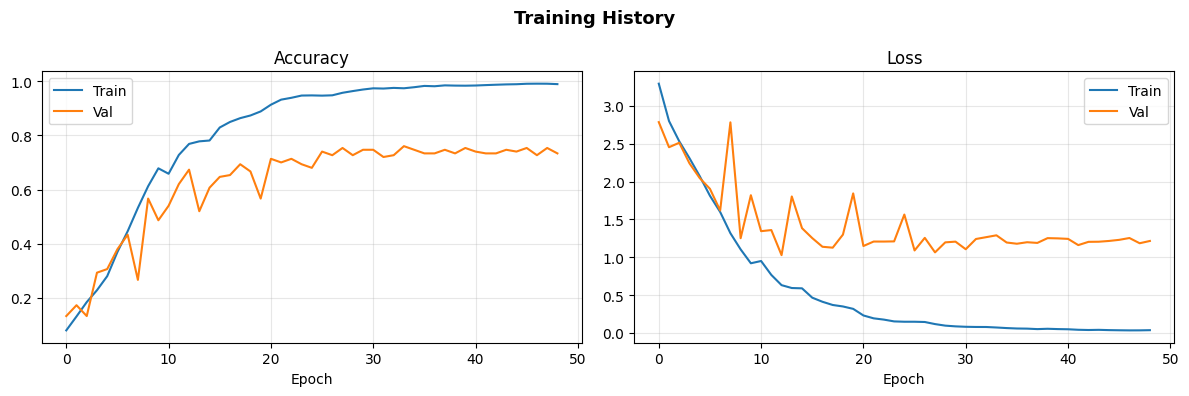

In [5]:
# Plot training and validation accuracy / loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'],     label='Train')
axes[0].plot(history.history['val_accuracy'], label='Val')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'],     label='Train')
axes[1].plot(history.history['val_loss'], label='Val')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Training History', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('processed_data/training_history.png', dpi=150)
plt.show()

In [6]:
# Evaluate on test set and save model metadata
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f'Test accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)')
print(f'Test loss     : {test_loss:.4f}')

with open('models/model_metadata.json', 'w') as f:
    json.dump({
        'model_type'      : 'BiLSTM',
        'sequence_length' : SEQ_LEN,
        'feature_size'    : FEAT_SIZE,
        'num_classes'     : NUM_CLASSES,
        'class_names'     : class_names,
        'test_accuracy'   : float(test_acc),
        'test_loss'       : float(test_loss),
        'epochs_trained'  : len(history.history['accuracy']),
        'best_val_accuracy': float(best_val_acc),
        'confidence_threshold': 0.7,
    }, f, indent=2)

print('Model saved : models/best_lstm_model.keras')
print('Metadata    : models/model_metadata.json')
print('\nProceed to Notebook 04.')

Test accuracy : 0.7133  (71.33%)
Test loss     : 1.5999
Model saved : models/best_lstm_model.keras
Metadata    : models/model_metadata.json

Proceed to Notebook 04.
